In [1]:
%pip install geopandas -q


StatementMeta(, 6ee92e9d-6fce-4404-8aa6-725a79b92080, 7, Finished, Available, Finished, True)


Note: you may need to restart the kernel to use updated packages.



StatementMeta(, 6ee92e9d-6fce-4404-8aa6-725a79b92080, 11, Finished, Available, Finished, False)

Écriture dans : /synfs/notebook/6ee92e9d-6fce-4404-8aa6-725a79b92080/silver/Files/carreaux
7759 carreaux | 569 IRIS (formes) | 569 IRIS (ménages)
Sauvegardé : fichier + table 'carreaux' dans lakehouse_silver


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

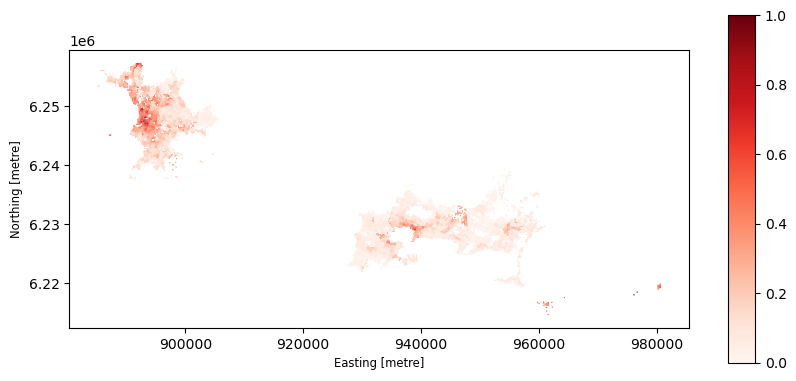

In [4]:
import geopandas as gpd, pandas as pd, os

# ---------- Paramètres ----------
BRONZE = "/lakehouse/default/Files"
notebookutils.fs.mount("abfss://citiz_hackathon@onelake.dfs.fabric.microsoft.com/lakehouse_silver.Lakehouse", "/silver")
SILVER = notebookutils.fs.getMountPath("/silver") + "/Files/carreaux"
os.makedirs(SILVER, exist_ok=True)
print("Écriture dans :", SILVER)

# ---------- 1. Lire les 3 fichiers bronze ----------
pop  = gpd.read_parquet(f"{BRONZE}/population/population_toulon_marseille.parquet").to_crs(2154).reset_index(drop=True)
iris = gpd.read_parquet(f"{BRONZE}/cartes/iris_toulon_marseille.parquet").to_crs(2154)
men  = pd.read_parquet(f"{BRONZE}/menages/menages_toulon_marseille.parquet")
print(len(pop), "carreaux |", len(iris), "IRIS (formes) |", len(men), "IRIS (ménages)")

# ---------- 2. Chaque carreau → son IRIS (par le centre du carreau) ----------
centres = pop[["geometry"]].copy()
centres["geometry"] = pop.centroid
j = gpd.sjoin(centres, iris[["CODE_IRIS", "geometry"]], how="left", predicate="within")
j = j[~j.index.duplicated()]
manquants = j["CODE_IRIS"].isna()
if manquants.any():                                   # centre dans la mer → IRIS le plus proche
    proche = gpd.sjoin_nearest(centres[manquants], iris[["CODE_IRIS", "geometry"]], how="left")
    proche = proche[~proche.index.duplicated()]
    j.loc[manquants, "CODE_IRIS"] = proche["CODE_IRIS"]
pop["code_iris"] = j["CODE_IRIS"].astype(str)

# ---------- 3. Ajouter la part de ménages sans voiture ----------
men["part_sans_voiture"] = (men.menages_sans_voiture / men.P21_MEN).where(men.P21_MEN > 0)
pop = pop.merge(men[["IRIS", "part_sans_voiture"]], left_on="code_iris", right_on="IRIS", how="left").drop(columns="IRIS")
pop["part_sans_voiture"] = pop.groupby("ville")["part_sans_voiture"].transform(lambda s: s.fillna(s.mean()))
pop["menages_sans_voiture_est"] = pop["men"] * pop["part_sans_voiture"]

# ---------- 4. Indicateurs utiles ----------
pop["densite_hab_km2"] = pop["ind"] * 25                       # 1 carreau = 0,04 km²
pop["revenu_moyen"]    = pop["ind_snv"] / pop["ind"]
pop["part_65_plus"]    = (pop["ind_65_79"] + pop["ind_80p"]) / pop["ind"]

# ---------- 5. Sauvegarder dans lakehouse_silver ----------
pop.to_parquet(f"{SILVER}/carreaux_toulon_marseille.parquet")

t = pd.DataFrame(pop.drop(columns="geometry"))
c = pop.centroid.to_crs(4326)
t["lon"], t["lat"] = c.x, c.y
t["wkt"] = pop.to_crs(4326).geometry.to_wkt()
for col in t.columns:
    if t[col].dtype == object: t[col] = t[col].astype(str)
sdf = spark.createDataFrame(t)
try:
    sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("lakehouse_silver.dbo.carreaux")
except Exception:
    sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("lakehouse_silver.carreaux")
print("Sauvegardé : fichier + table 'carreaux' dans lakehouse_silver")

# ---------- 6. Carte : part de ménages sans voiture ----------
pop.plot(column="part_sans_voiture", cmap="Reds", legend=True, figsize=(10, 7))

In [5]:
r = pop.groupby("ville").agg(carreaux=("ind", "size"), habitants=("ind", "sum"),
                             menages=("men", "sum"), sans_voiture=("menages_sans_voiture_est", "sum"))
r["part_sans_voiture_%"] = (100 * r.sans_voiture / r.menages).round(1)
r[["habitants", "menages", "sans_voiture"]] = r[["habitants", "menages", "sans_voiture"]].round(0).astype(int)
print("Carreaux sans IRIS :", (pop.code_iris == "nan").sum())
print(r)

StatementMeta(, 6ee92e9d-6fce-4404-8aa6-725a79b92080, 12, Finished, Available, Finished, False)

Carreaux sans IRIS : 0
           carreaux  habitants  menages  sans_voiture  part_sans_voiture_%
ville                                                                     
marseille      3148     772114   362392        115716                 31.9
toulon         4611     417066   205697         37868                 18.4
